Customer Churn Prediction | Machine Learning

Developed an end-to-end Machine Learning project to predict customer churn and identify customers who are likely to discontinue a company's services.

Analyzed customer data containing 7,043 records and 21 features using Python and Pandas.

Performed data cleaning, preprocessing, and Exploratory Data Analysis (EDA).

Applied data visualization techniques to understand customer behavior and churn patterns.

Built and evaluated classification models using Scikit-learn.

Performed model tuning to improve prediction performance.

Developed an interactive web application using Streamlit to predict customer churn.

Saved the trained machine learning model using Pickle.

Technologies Used: Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Streamlit, Pickle.

Outcome: Built an interactive machine learning application that predicts customer churn and displays churn probabilities, helping businesses identify customers who may leave and support customer retention strategies.

In [1]:
import pandas as pd

In [2]:
df=pd.read_csv(r"C:\Users\sajal\Desktop\ML\datasets\WA_Fn-UseC_-Telco-Customer-Churn (1).csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
df.value_counts().sum()

7043

In [7]:
df.columns.to_list()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [8]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
df.shape

(7043, 21)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [10]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [11]:
df.duplicated().sum()

0

In [12]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [13]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print(df["TotalCharges"].isnull().sum())

11


In [14]:
df["TotalCharges"].isnull().sum()

11

In [15]:
# Remove rows with missing TotalCharges
df = df.dropna(subset=["TotalCharges"])

# Check the new dataset size
print(df.shape)

# Confirm missing values are handled
print(df["TotalCharges"].isnull().sum())

(7032, 21)
0


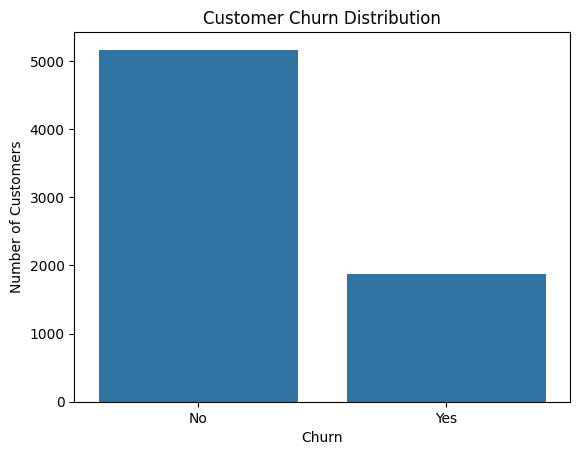

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [16]:
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

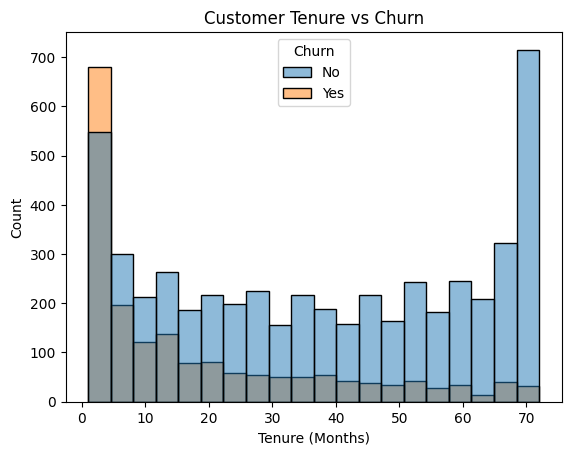

In [21]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=20)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Tenure (Months)")

plt.show()

Text(0, 0.5, 'Monthly Charges')

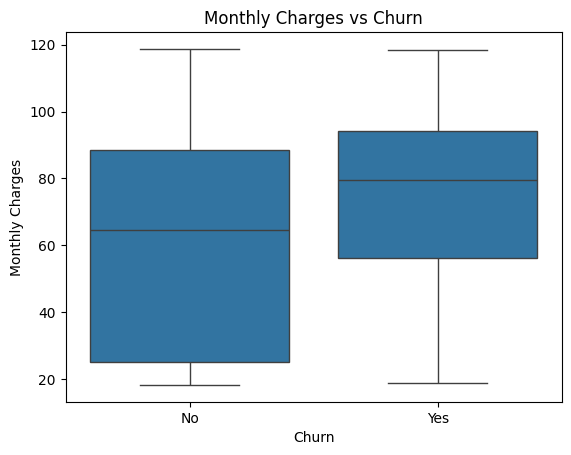

In [24]:
sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

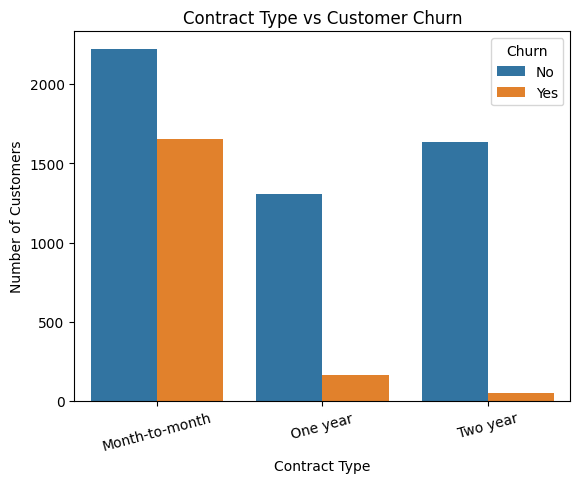

In [25]:
sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Contract Type vs Customer Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.show()

In [26]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.722826  11.277174
Two year        97.151335   2.848665


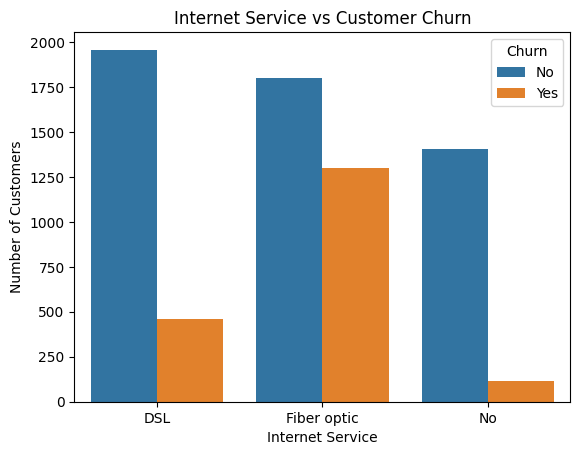

In [27]:
sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Internet Service vs Customer Churn")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

In [28]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn)

Churn                   No        Yes
InternetService                      
DSL              81.001656  18.998344
Fiber optic      58.107235  41.892765
No               92.565789   7.434211


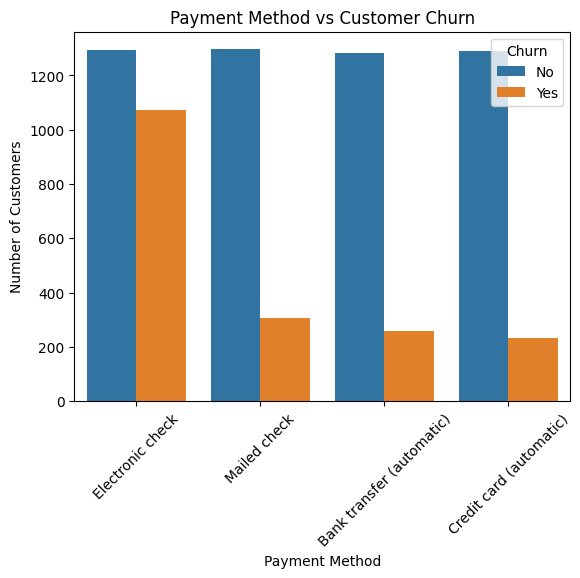

In [29]:
sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Payment Method vs Customer Churn")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.show()

In [30]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn)

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.268482  16.731518
Credit card (automatic)    84.746877  15.253123
Electronic check           54.714588  45.285412
Mailed check               80.798005  19.201995


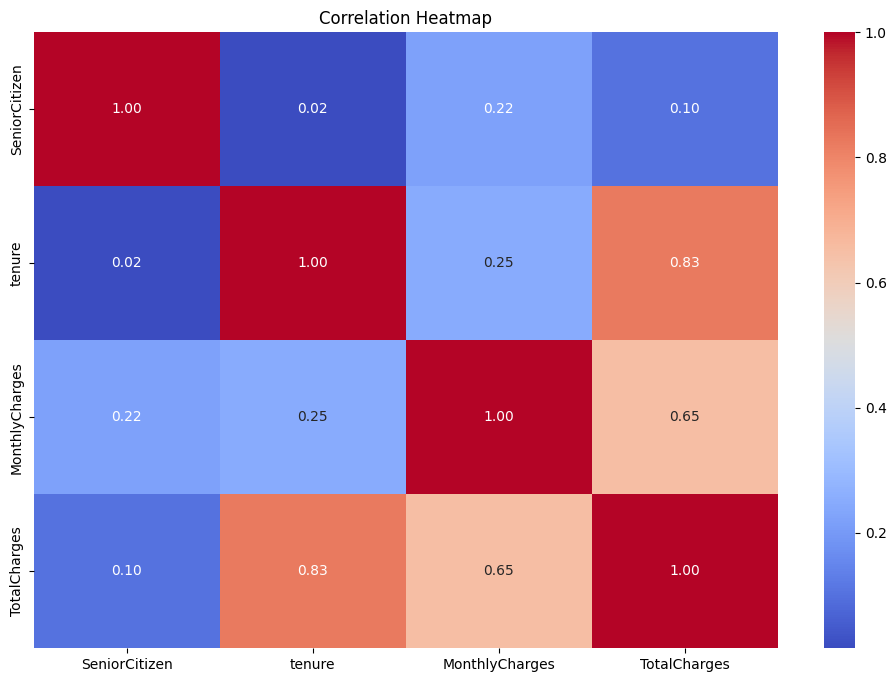

In [31]:
numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [32]:
df = df.drop("customerID", axis=1)

print(df.head())

   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1              Yes          No  

In [33]:
X = df.drop("Churn", axis=1)

y = df["Churn"]

In [34]:
print(X.shape)
print(y.shape)

(7032, 19)
(7032,)


In [35]:
numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_cols = X.select_dtypes(
    include=["object"]
).columns

print("Numerical columns:")
print(numerical_cols)

print("Categorical columns:")
print(categorical_cols)

Numerical columns:
Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')
Categorical columns:
Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')


In [36]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore")

print("Encoder created successfully")

Encoder created successfully


In [37]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

print("Scaler created successfully")

Scaler created successfully


In [38]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

print("Preprocessing pipeline created successfully")

Preprocessing pipeline created successfully


In [39]:
from sklearn.model_selection import train_test_split

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [41]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (5625, 19)
Testing data: (1407, 19)
Training target: (5625,)
Testing target: (1407,)


In [42]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [43]:
y_pred = lr_model.predict(X_test)

print(y_pred[:10])

['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No']


In [44]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100)

Accuracy: 0.8038379530916845
Accuracy percentage: 80.38379530916845


In [45]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1033
         Yes       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



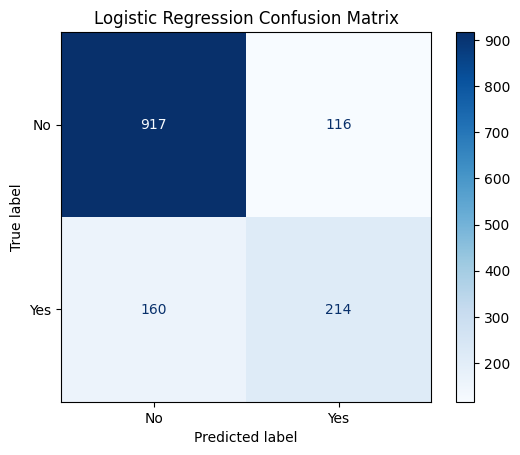

In [46]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

display.plot(cmap="Blues")

plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [47]:
from sklearn.tree import DecisionTreeClassifier

dt_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

In [48]:
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [49]:
dt_pred = dt_model.predict(X_test)

print(dt_pred[:10])

['No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No']


In [50]:
from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy * 100)

Decision Tree Accuracy: 73.0632551528074


In [51]:
from sklearn.metrics import classification_report

print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

          No       0.82      0.82      0.82      1033
         Yes       0.49      0.50      0.50       374

    accuracy                           0.73      1407
   macro avg       0.66      0.66      0.66      1407
weighted avg       0.73      0.73      0.73      1407



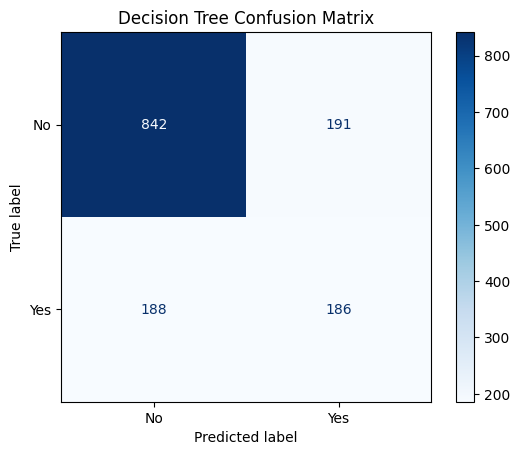

In [52]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_pred,
    labels=["No", "Yes"],
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Decision Tree Confusion Matrix")
plt.show()

In [53]:
print("Logistic Regression:", accuracy * 100)
print("Decision Tree:", dt_accuracy * 100)

Logistic Regression: 80.38379530916845
Decision Tree: 73.0632551528074


In [54]:

from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

In [55]:
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [56]:
rf_pred = rf_model.predict(X_test)

print(rf_pred[:10])

['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No']


In [57]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy * 100)

Random Forest Accuracy: 78.74911158493248


In [58]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

          No       0.83      0.90      0.86      1033
         Yes       0.63      0.48      0.55       374

    accuracy                           0.79      1407
   macro avg       0.73      0.69      0.70      1407
weighted avg       0.78      0.79      0.78      1407



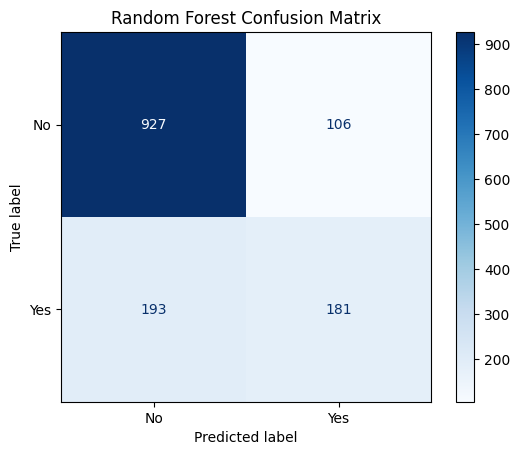

In [59]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    labels=["No", "Yes"],
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.show()

In [60]:
print("Logistic Regression:", accuracy_score(y_test, y_pred) * 100)

print("Decision Tree:", accuracy_score(y_test, dt_pred) * 100)

print("Random Forest:", accuracy_score(y_test, rf_pred) * 100)

Logistic Regression: 80.38379530916845
Decision Tree: 73.0632551528074
Random Forest: 78.74911158493248


In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [62]:
models = {
    "Logistic Regression": (lr_model, y_pred),
    "Decision Tree": (dt_model, dt_pred),
    "Random Forest": (rf_model, rf_pred)
}

results = []

for name, (model, predictions) in models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label="Yes"
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label="Yes"
        ),
        "F1 Score": f1_score(
            y_test, predictions, pos_label="Yes"
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == "Yes").astype(int),
            model.predict_proba(X_test)[:, 1]
        )
    })

comparison_df = pd.DataFrame(results)
print(comparison_df.round(3))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression     0.804      0.648   0.572     0.608    0.836
1        Decision Tree     0.731      0.493   0.497     0.495    0.656
2        Random Forest     0.787      0.631   0.484     0.548    0.814


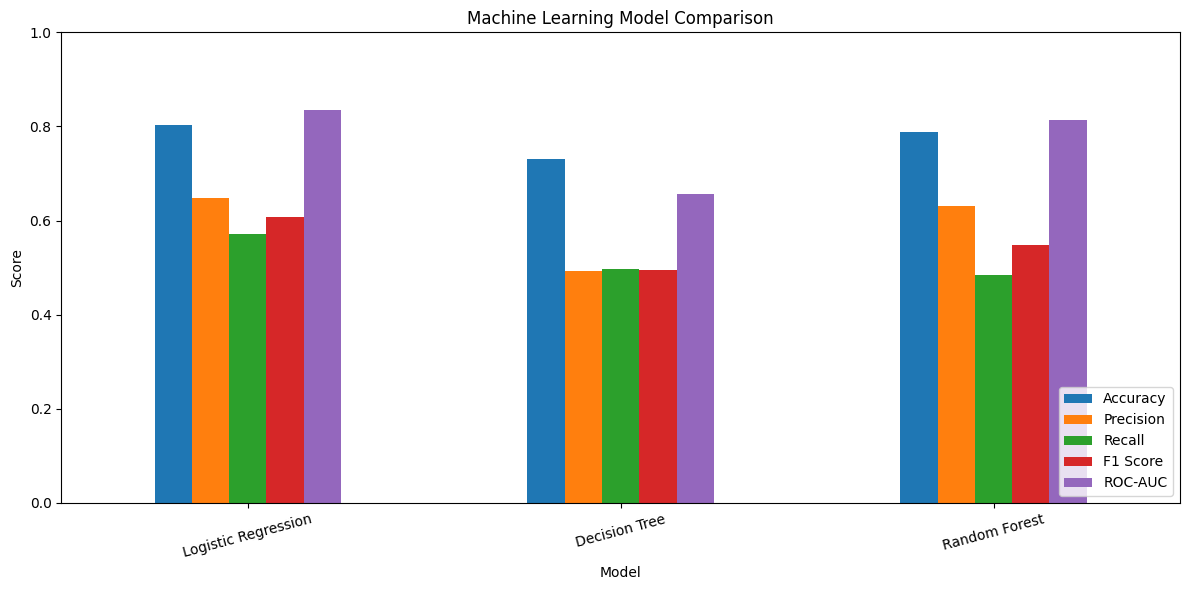

In [63]:
comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [64]:
best_model_name = comparison_df.loc[
    comparison_df["F1 Score"].idxmax(), "Model"
]

print("Best model based on F1-score:", best_model_name)

Best model based on F1-score: Logistic Regression


In [65]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

In [ ]:
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None],
    "model__min_samples_split": [2, 5]
}

In [67]:
rf_grid = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

In [68]:
rf_grid.fit(X_train, y_train)

print("Hyperparameter tuning completed!")

Fitting 5 folds for each of 12 candidates, totalling 60 fits


c:\Users\sajal\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_search.py:1051: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


Hyperparameter tuning completed!


In [69]:
print("Best Parameters:")
print(rf_grid.best_params_)

print("Best Cross Validation F1 Score:")
print(rf_grid.best_score_)

Best Parameters:
{'model__max_depth': 5, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best Cross Validation F1 Score:
nan


In [71]:
best_rf_model = rf_grid.best_estimator_

tuned_pred = best_rf_model.predict(X_test)

print(classification_report(y_test, tuned_pred))

              precision    recall  f1-score   support

          No       0.81      0.92      0.86      1033
         Yes       0.65      0.42      0.51       374

    accuracy                           0.78      1407
   macro avg       0.73      0.67      0.68      1407
weighted avg       0.77      0.78      0.77      1407



In [72]:
print(
    "Tuned Random Forest Accuracy:",
    accuracy_score(y_test, tuned_pred) * 100
)

Tuned Random Forest Accuracy: 78.46481876332622


In [73]:
final_models = {
    "Logistic Regression": y_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "Tuned Random Forest": tuned_pred
}

final_results = []

for name, predictions in final_models.items():

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label="Yes"
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label="Yes"
        ),
        "F1 Score": f1_score(
            y_test, predictions, pos_label="Yes"
        )
    })

final_comparison = pd.DataFrame(final_results)

print(final_comparison.round(3))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.804      0.648   0.572     0.608
1        Decision Tree     0.731      0.493   0.497     0.495
2        Random Forest     0.787      0.631   0.484     0.548
3  Tuned Random Forest     0.785      0.647   0.417     0.507


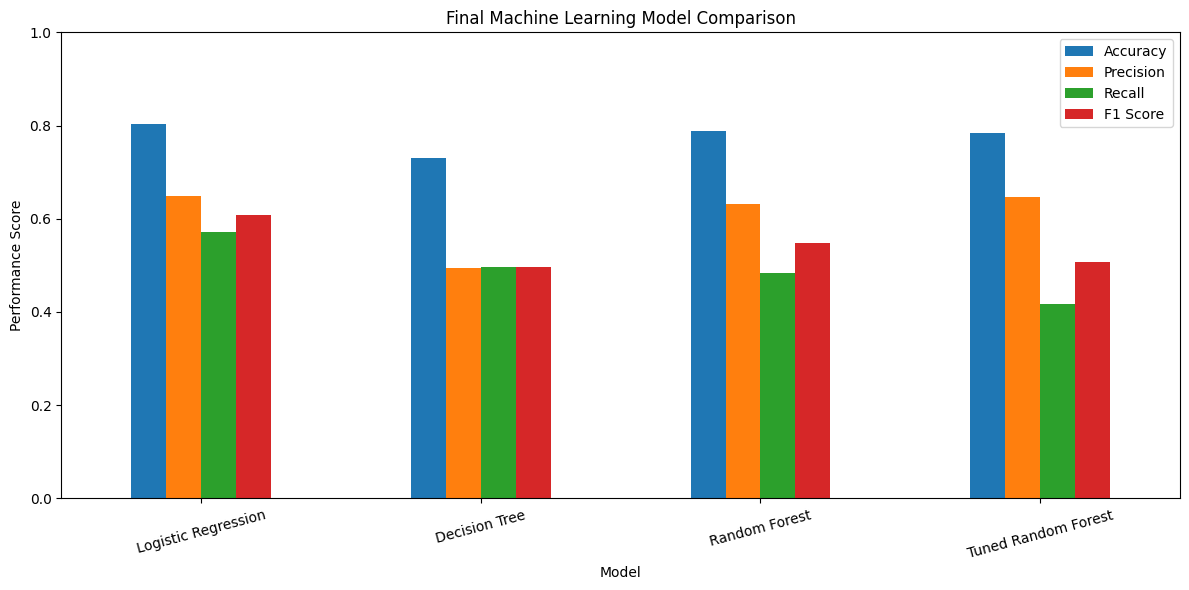

In [74]:
final_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Final Machine Learning Model Comparison")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [75]:
best_index = final_comparison["F1 Score"].idxmax()

print("Best Model:")
print(final_comparison.loc[best_index])

Best Model:
Model        Logistic Regression
Accuracy                0.803838
Precision               0.648485
Recall                  0.572193
F1 Score                0.607955
Name: 0, dtype: object


In [76]:
import joblib

best_model = best_rf_model

joblib.dump(best_model, "customer_churn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [78]:
# Get the trained Random Forest model
rf = best_rf_model.named_steps["model"]

# Get the preprocessing step
preprocessor_fitted = best_rf_model.named_steps["preprocessing"]

# Get transformed feature names
feature_names = preprocessor_fitted.get_feature_names_out()

# Get feature importance scores
importance = rf.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort features
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_df.head(15))

                                     Feature  Importance
36              cat__Contract_Month-to-month    0.157470
1                                num__tenure    0.145768
16          cat__InternetService_Fiber optic    0.089506
18                    cat__OnlineSecurity_No    0.087885
3                          num__TotalCharges    0.080800
43       cat__PaymentMethod_Electronic check    0.070053
27                       cat__TechSupport_No    0.059145
38                    cat__Contract_Two year    0.049885
2                        num__MonthlyCharges    0.030026
21                      cat__OnlineBackup_No    0.025271
37                    cat__Contract_One year    0.021499
34  cat__StreamingMovies_No internet service    0.019012
24                  cat__DeviceProtection_No    0.016424
15                  cat__InternetService_DSL    0.015807
29                      cat__TechSupport_Yes    0.015604


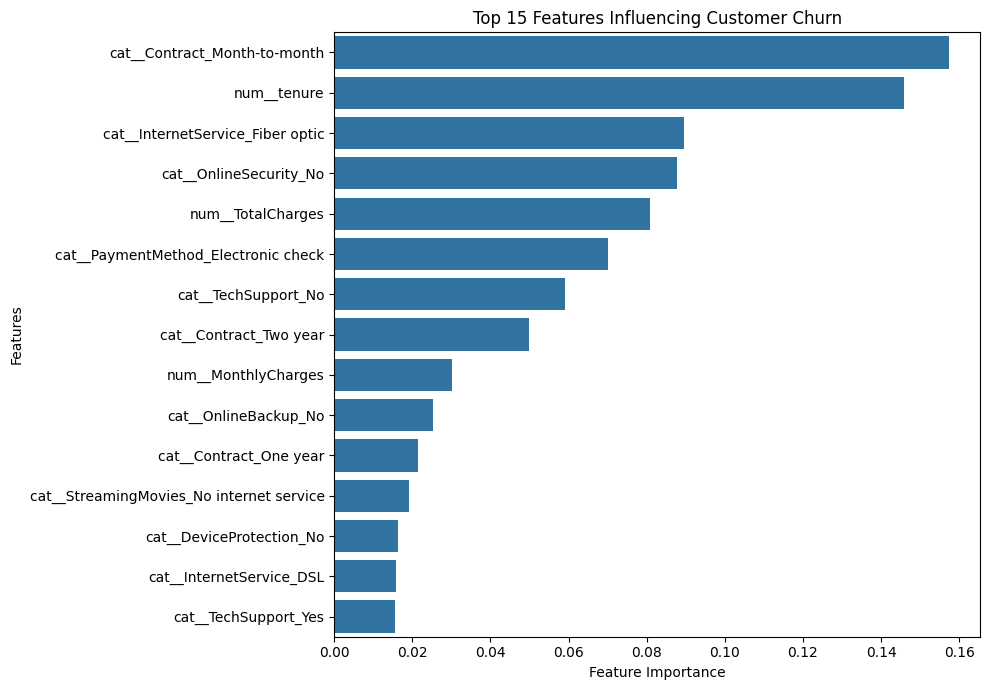

In [79]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Influencing Customer Churn")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [80]:
import joblib

In [81]:
best_model = best_rf_model

In [82]:
joblib.dump(
    best_model,
    "customer_churn_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [83]:
loaded_model = joblib.load("customer_churn_model.pkl")

print("Model loaded successfully!")

Model loaded successfully!


In [84]:
sample_prediction = loaded_model.predict(X_test.iloc[:5])

print(sample_prediction)

['No' 'Yes' 'No' 'No' 'No']


In [85]:
pip install streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [86]:
import streamlit as st
import pandas as pd
import joblib

# Load the trained machine learning model
model = joblib.load("customer_churn_model.pkl")

# Page settings
st.set_page_config(
    page_title="Customer Churn Prediction",
    page_icon="📊"
)

st.title("Customer Churn Prediction")
st.write("Enter customer details to predict whether they may leave the company.")

with st.form("customer_form"):

    st.subheader("Customer Information")

    col1, col2 = st.columns(2)

    with col1:
        gender = st.selectbox("Gender", ["Female", "Male"])
        SeniorCitizen = st.selectbox("Senior Citizen", [0, 1])
        Partner = st.selectbox("Partner", ["Yes", "No"])
        Dependents = st.selectbox("Dependents", ["Yes", "No"])
        tenure = st.slider("Tenure (months)", 0, 72, 12)
        PhoneService = st.selectbox("Phone Service", ["Yes", "No"])
        MultipleLines = st.selectbox(
            "Multiple Lines",
            ["No phone service", "No", "Yes"]
        )
        InternetService = st.selectbox(
            "Internet Service",
            ["DSL", "Fiber optic", "No"]
        )
        OnlineSecurity = st.selectbox(
            "Online Security",
            ["No", "Yes", "No internet service"]
        )

    with col2:
        OnlineBackup = st.selectbox(
            "Online Backup",
            ["No", "Yes", "No internet service"]
        )
        DeviceProtection = st.selectbox(
            "Device Protection",
            ["No", "Yes", "No internet service"]
        )
        TechSupport = st.selectbox(
            "Tech Support",
            ["No", "Yes", "No internet service"]
        )
        StreamingTV = st.selectbox(
            "Streaming TV",
            ["No", "Yes", "No internet service"]
        )
        StreamingMovies = st.selectbox(
            "Streaming Movies",
            ["No", "Yes", "No internet service"]
        )
        Contract = st.selectbox(
            "Contract",
            ["Month-to-month", "One year", "Two year"]
        )
        PaperlessBilling = st.selectbox(
            "Paperless Billing", ["Yes", "No"]
        )
        PaymentMethod = st.selectbox(
            "Payment Method",
            [
                "Electronic check",
                "Mailed check",
                "Bank transfer (automatic)",
                "Credit card (automatic)"
            ]
        )
        MonthlyCharges = st.number_input(
            "Monthly Charges", min_value=0.0, value=50.0
        )
        TotalCharges = st.number_input(
            "Total Charges", min_value=0.0, value=500.0
        )

    submitted = st.form_submit_button("Predict Churn")

if submitted:

    customer = pd.DataFrame([{
        "gender": gender,
        "SeniorCitizen": SeniorCitizen,
        "Partner": Partner,
        "Dependents": Dependents,
        "tenure": tenure,
        "PhoneService": PhoneService,
        "MultipleLines": MultipleLines,
        "InternetService": InternetService,
        "OnlineSecurity": OnlineSecurity,
        "OnlineBackup": OnlineBackup,
        "DeviceProtection": DeviceProtection,
        "TechSupport": TechSupport,
        "StreamingTV": StreamingTV,
        "StreamingMovies": StreamingMovies,
        "Contract": Contract,
        "PaperlessBilling": PaperlessBilling,
        "PaymentMethod": PaymentMethod,
        "MonthlyCharges": MonthlyCharges,
        "TotalCharges": TotalCharges
    }])

    prediction = model.predict(customer)[0]

    yes_index = list(model.classes_).index("Yes")
    probability = model.predict_proba(customer)[0][yes_index]

    st.subheader("Prediction Result")

    if prediction == "Yes":
        st.error("This customer is likely to churn.")
    else:
        st.success("This customer is unlikely to churn.")

    st.metric("Churn Probability", f"{probability:.2%}")


2026-10-31 21:05:09.157 
  command:

    streamlit run C:\Users\sajal\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-31 21:05:09.170 Session state does not function when running a script without `streamlit run`
